# Actividad 5 — Clasificación de abandono bancario
**Datos sintéticos, 800 registros.** Comparación de regresión logística y random forest, validación cruzada 5-fold, GridSearchCV y MLflow. No se usan datos reales.

## 1. Preparar el proyecto
Sube el archivo `Actividad5_repositorio.zip` a Colab cuando se solicite. El notebook descomprime el proyecto, instala dependencias y ejecuta el entrenamiento. La GPU no es necesaria para estos modelos scikit-learn.

## Cargar los archivos del proyecto en Colab
Sube `Actividad5_entrega.zip` (archivo de esta entrega). Así funciona antes de crear el repositorio remoto. Alternativamente, clona tu repositorio una vez publicado.

In [2]:
import os
import subprocess
from pathlib import Path

# Dirección correcta de tu repositorio
URL_GITHUB = (
    "https://github.com/Juanspter/"
    "Predicci-n-de-abandono-de-clientes-bancarios.git"
)

# Carpeta local que utilizará el notebook
REPO = Path("/content/Actividad5")

# Descargar el proyecto si todavía no existe
if not REPO.exists():
    subprocess.run(
        ["git", "clone", URL_GITHUB, str(REPO)],
        check=True
    )

# Cambiar al directorio del proyecto
os.chdir(REPO)

print("Proyecto cargado correctamente")
print("Carpeta actual:", os.getcwd())
print("Archivos disponibles:")

for archivo in sorted(os.listdir(REPO)):
    print(" -", archivo)


Proyecto cargado correctamente
Carpeta actual: /content/Actividad5
Archivos disponibles:
 - .git
 - .gitignore
 - CHANGELOG.md
 - README.md
 - datos
 - docs
 - evidencias
 - fuentes
 - reportes
 - requirements.txt
 - resultados


In [3]:
%pip install -q -r /content/Actividad5/requirements.txt

import mlflow
import sklearn
import pandas as pd

print("Dependencias instaladas correctamente")
print("MLflow:", mlflow.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jupyter-kernel-gateway 2.5.2 requires notebook<7.0,>=5.7.6, but you have notebook 7.6.3 which is incompatible.
Dependencias instaladas correctamente
MLflow: 3.17.2
Scikit-learn: 1.6.1
Pandas: 2.2.3


In [9]:
import pandas as pd
from pathlib import Path
from fuentes.datos_prep import preparar_archivo

# 1. Carpeta principal del proyecto
base = Path("/content/Actividad5")

# 2. Rutas de los datasets
archivo_original = (
    base / "datos/datos_ini/clientes_sinteticos_v1.csv"
)

archivo_limpio = (
    base / "datos/datos_limp/clientes_limpios_v1.csv"
)

# 3. Verificar archivo original
print("Archivo original encontrado:", archivo_original.exists())

# 4. Ejecutar preparación de datos
preparar_archivo(base)

# 5. Verificar que se generó el archivo limpio
print("Archivo limpio encontrado:", archivo_limpio.exists())

if not archivo_limpio.exists():
    raise FileNotFoundError(
        f"No se generó el archivo limpio: {archivo_limpio}"
    )

# 6. Cargar el dataset limpio
df = pd.read_csv(archivo_limpio)

# 7. Mostrar resultados
print("\nDataset preparado correctamente")
print("Dimensiones:", df.shape)

print("\nDistribución de abandono:")
print(df["abandono"].value_counts().to_dict())

print("\nPrimeros cinco registros:")
display(df.head())

Archivo original encontrado: True
Archivo limpio encontrado: True

Dataset preparado correctamente
Dimensiones: (800, 11)

Distribución de abandono:
{0: 700, 1: 100}

Primeros cinco registros:


,cliente_id,edad,antiguedad_anios,num_productos,saldo_mxn,cliente_activo,transacciones_digitales_mes,reclamaciones_12m,region,segmento,abandono
0,SYN00000,67,14,2,69703.58,0,14.0,2,Norte,Masivo,0
1,SYN00001,29,3,2,150552.63,1,13.0,1,Centro,Masivo,0
2,SYN00002,20,10,2,69203.18,1,14.0,2,Centro,Masivo,0
3,SYN00003,55,4,2,136577.05,1,10.0,1,Sur,Masivo,1
4,SYN00004,39,8,1,111489.86,1,12.0,0,Norte,Masivo,0


## 3. Visualizaciones y control de calidad

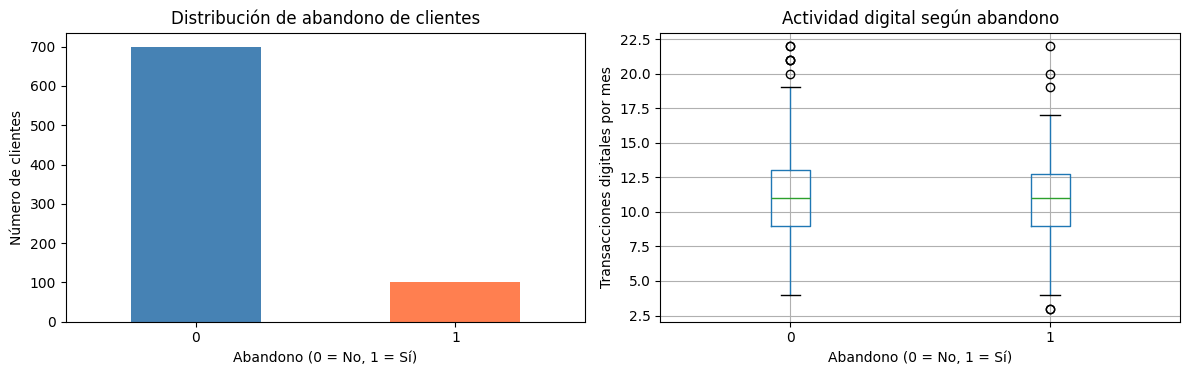

In [11]:
import matplotlib.pyplot as plt

# Crear dos gráficos
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Distribución de abandono
df["abandono"].value_counts().sort_index().plot.bar(
    ax=ax[0],
    color=["steelblue", "coral"]
)

ax[0].set_title("Distribución de abandono de clientes")
ax[0].set_xlabel("Abandono (0 = No, 1 = Sí)")
ax[0].set_ylabel("Número de clientes")
ax[0].tick_params(axis="x", rotation=0)

# Gráfico 2: Actividad digital según abandono
df.boxplot(
    column="transacciones_digitales_mes",
    by="abandono",
    ax=ax[1]
)

ax[1].set_title("Actividad digital según abandono")
ax[1].set_xlabel("Abandono (0 = No, 1 = Sí)")
ax[1].set_ylabel("Transacciones digitales por mes")

plt.suptitle("")
plt.tight_layout()
plt.show()

In [17]:

from pathlib import Path

archivo = Path("/content/Actividad5/fuentes/train.py")

lineas = archivo.read_text(encoding="utf-8").splitlines()

for numero, linea in enumerate(lineas, start=1):
    if (
        "mlflow" in linea.lower()
        or "tracking_uri" in linea.lower()
        or "mlruns" in linea.lower()
    ):
        print(f"Línea {numero}: {linea}")


Línea 1: """Entrenamiento de churn sintético con GridSearchCV y MLflow.
Línea 28: def ejecutar(raiz, usar_mlflow=True):
Línea 39:     mlflow=None
Línea 40:     if usar_mlflow:
Línea 42:             import mlflow
Línea 43:             import mlflow.sklearn
Línea 45:             raise RuntimeError("Instala MLflow con: pip install -r requirements.txt") from e
Línea 46:         mlflow.set_tracking_uri((raiz/"mlruns").as_uri())
Línea 47:         mlflow.set_experiment("Actividad5_Churn_Sintetico")
Línea 60:         if mlflow:
Línea 61:             with mlflow.start_run(run_name=nombre):
Línea 62:                 mlflow.log_params(busqueda.best_params_)
Línea 63:                 mlflow.log_param("dataset_version","v1_sintetico")
Línea 64:                 mlflow.log_param("cv_folds",5)
Línea 65:                 mlflow.log_param("random_state",42)
Línea 66:                 mlflow.log_metrics({k:float(row[k]) for k in ["accuracy","precision","recall","f1","roc_auc","cv_auc_media","cv_auc_sd"]})


In [18]:
from pathlib import Path

# Archivo que vamos a corregir
archivo = Path("/content/Actividad5/fuentes/train.py")

# Leer el código original
codigo = archivo.read_text(encoding="utf-8")

# Configuración antigua identificada en la línea 46
anterior = 'mlflow.set_tracking_uri((raiz/"mlruns").as_uri())'

# Nueva configuración SQLite
nuevo = 'mlflow.set_tracking_uri(f"sqlite:///{raiz / \'mlflow.db\'}")'

# Reemplazar únicamente la configuración antigua
if anterior in codigo:
    codigo = codigo.replace(anterior, nuevo, 1)
    archivo.write_text(codigo, encoding="utf-8")
    print("Configuración de MLflow actualizada correctamente.")
else:
    print("La configuración antigua no se encontró.")

# Verificar la modificación
for numero, linea in enumerate(
    archivo.read_text(encoding="utf-8").splitlines(),
    start=1
):
    if "set_tracking_uri" in linea:
        print(f"Línea {numero}: {linea}")


Configuración de MLflow actualizada correctamente.
Línea 46:         mlflow.set_tracking_uri(f"sqlite:///{raiz / 'mlflow.db'}")


In [20]:
from pathlib import Path

# Archivo de entrenamiento
archivo = Path("/content/Actividad5/fuentes/train.py")

codigo = archivo.read_text(encoding="utf-8")

# Instrucción anterior
anterior = (
    'mlflow.sklearn.log_model('
    'busqueda.best_estimator_,artifact_path="modelo")'
)

# Nueva instrucción compatible
nuevo = (
    'mlflow.sklearn.log_model('
    'busqueda.best_estimator_,'
    'name="modelo",'
    'serialization_format="cloudpickle")'
)

if anterior in codigo:
    codigo = codigo.replace(anterior, nuevo, 1)
    archivo.write_text(codigo, encoding="utf-8")
    print("Configuración de guardado del modelo corregida.")
else:
    print("No se encontró la instrucción exacta.")

# Verificar el cambio
for numero, linea in enumerate(
    archivo.read_text(encoding="utf-8").splitlines(),
    start=1
):
    if "mlflow.sklearn.log_model" in linea:
        print(f"Línea {numero}: {linea}")

Configuración de guardado del modelo corregida.
Línea 69:                 mlflow.sklearn.log_model(busqueda.best_estimator_,name="modelo",serialization_format="cloudpickle")


## 4. Entrenar, optimizar y registrar en MLflow
Ejecuta ambos modelos y registra parámetros, métricas y artefactos. El tracking queda en `/content/Actividad5/mlruns`.

In [21]:
import os

os.chdir("/content/Actividad5")

print("Iniciando entrenamiento y registro en MLflow...")

!python fuentes/train.py

Iniciando entrenamiento y registro en MLflow...
2026/10/26 04:33:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/26 04:33:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
             modelo  accuracy  precision  recall  f1  roc_auc  cv_auc_media  cv_auc_sd  n_train  n_test                                               

## 5. Comparar resultados

RESULTADOS COMPARATIVOS


,modelo,accuracy,precision,recall,f1,roc_auc,cv_auc_media,cv_auc_sd,mejores_parametros
0,Regresion_logistica,0.875,0.0,0.0,0.0,0.770743,0.732190,0.083401,"{""clasificador__C"": 0.1, ""clasificador__class_..."
1,Random_forest,0.875,0.0,0.0,0.0,0.747657,0.708317,0.066430,"{""clasificador__max_depth"": 4, ""clasificador__..."



COMPARACIÓN DE CURVAS ROC


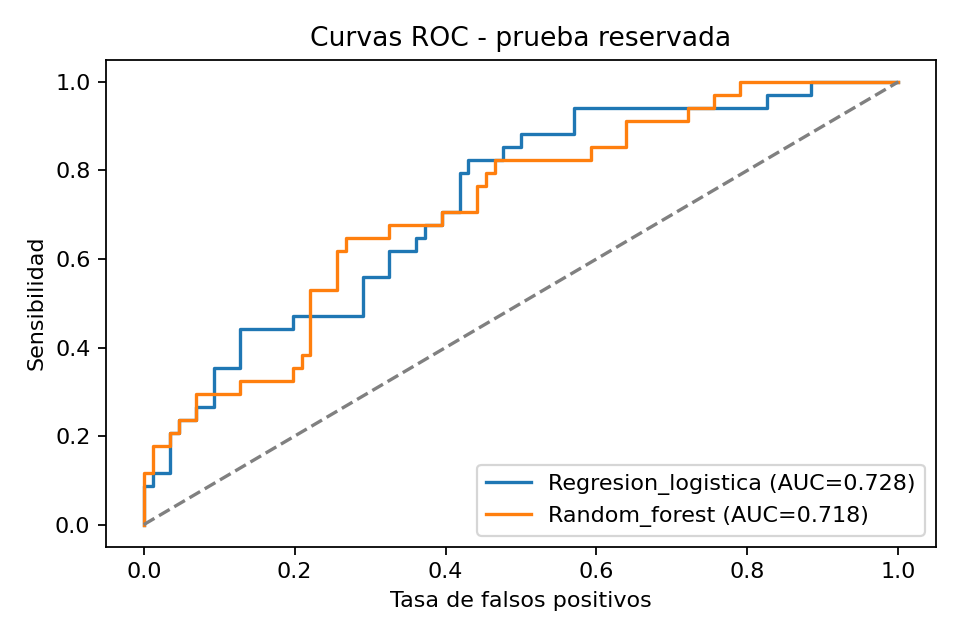

In [23]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display

# Carpeta principal del proyecto
base = Path("/content/Actividad5")

# Leer resultados del entrenamiento
archivo = base / "resultados/comparacion_modelos.csv"
res = pd.read_csv(archivo)

print("RESULTADOS COMPARATIVOS")
print("=" * 60)

# Columnas que realmente genera train.py
columnas = [
    "modelo",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "cv_auc_media",
    "cv_auc_sd",
    "mejores_parametros"
]

# Comprobar las columnas disponibles
disponibles = [c for c in columnas if c in res.columns]

display(res[disponibles])

# Mostrar gráfica ROC
grafica = base / "resultados/roc_comparacion.png"

if grafica.exists():
    print("\nCOMPARACIÓN DE CURVAS ROC")
    display(Image(filename=str(grafica)))
else:
    print("La gráfica ROC no se encontró.")

## 6. Verificar registros de MLflow (sin interfaz)

In [25]:
import mlflow
from pathlib import Path
from IPython.display import display

base = Path("/content/Actividad5")
db = base / "mlflow.db"

mlflow.set_tracking_uri(f"sqlite:///{db}")

experimento = mlflow.get_experiment_by_name(
    "Actividad5_Churn_Sintetico"
)

if experimento is None:
    raise ValueError("No se encontró el experimento.")

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

print("Experimento:", experimento.name)
print("Total de ejecuciones:", len(runs))

columnas = [
    "tags.mlflow.runName",
    "status",
    "metrics.accuracy",
    "metrics.f1",
    "metrics.roc_auc",
    "metrics.cv_auc_media"
]

columnas = [c for c in columnas if c in runs.columns]

display(runs[columnas])

completadas = runs[runs["status"] == "FINISHED"]
print("Ejecuciones completadas:", len(completadas))


Experimento: Actividad5_Churn_Sintetico
Total de ejecuciones: 4


,tags.mlflow.runName,status,metrics.accuracy,metrics.f1,metrics.roc_auc,metrics.cv_auc_media
0,comparacion_global,FINISHED,NaN,NaN,NaN,NaN
1,Random_forest,FINISHED,0.875,0.0,0.747657,0.708317
2,Regresion_logistica,FINISHED,0.875,0.0,0.770743,0.732190
3,Regresion_logistica,FAILED,0.875,0.0,0.770743,0.732190


Ejecuciones completadas: 3


In [26]:
#verificación de parámetros y artecfactos
from mlflow.tracking import MlflowClient

cliente = MlflowClient()

for _, fila in runs.iterrows():
    if fila["status"] != "FINISHED":
        continue

    run_id = fila["run_id"]
    nombre = fila.get("tags.mlflow.runName", run_id)

    detalle = cliente.get_run(run_id)

    print("\n" + "=" * 55)
    print("EJECUCIÓN:", nombre)
    print("RUN ID:", run_id)

    print("\nPARÁMETROS:")
    print(detalle.data.params)

    print("\nMÉTRICAS:")
    print(detalle.data.metrics)

    print("\nARTEFACTOS:")
    for artefacto in cliente.list_artifacts(run_id):
        print("-", artefacto.path)



EJECUCIÓN: comparacion_global
RUN ID: ec31974060cc470eb3a275b01d8af4c0

PARÁMETROS:
{}

MÉTRICAS:
{}

ARTEFACTOS:
- comparacion_estadistica.json
- comparacion_modelos.csv
- curvas_roc.png

EJECUCIÓN: Random_forest
RUN ID: 3b0f1425ce354cb89177d49726ebbbef

PARÁMETROS:
{'clasificador__max_depth': '4', 'clasificador__min_samples_leaf': '1', 'clasificador__n_estimators': '200', 'dataset_version': 'v1_sintetico', 'cv_folds': '5', 'random_state': '42'}

MÉTRICAS:
{'accuracy': 0.875, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.7476571428571429, 'cv_auc_media': 0.7083174603174603, 'cv_auc_sd': 0.06642981357052997}

ARTEFACTOS:
- confusion_Random_forest.csv
- predicciones_Random_forest.csv

EJECUCIÓN: Regresion_logistica
RUN ID: 3d1f1fcdac5c4d3b81e3c1252d80a2ed

PARÁMETROS:
{'clasificador__C': '0.1', 'clasificador__class_weight': 'None', 'dataset_version': 'v1_sintetico', 'cv_folds': '5', 'random_state': '42'}

MÉTRICAS:
{'accuracy': 0.875, 'precision': 0.0, 'recall': 0.0, 'f1': 0

In [27]:
#modelos guardados mlflow
from mlflow.tracking import MlflowClient

cliente = MlflowClient()

print("MODELOS ASOCIADOS A LAS EJECUCIONES")
print("=" * 55)

for _, fila in runs.iterrows():
    if fila["status"] != "FINISHED":
        continue

    nombre = fila.get("tags.mlflow.runName", "Sin nombre")
    run_id = fila["run_id"]

    detalle = cliente.get_run(run_id)

    print(f"\nEjecución: {nombre}")
    print("Run ID:", run_id)

    modelos = detalle.outputs.model_outputs

    if modelos:
        for modelo in modelos:
            print("Modelo registrado:", modelo.model_id)
    else:
        print("Sin modelos asociados en model_outputs")

MODELOS ASOCIADOS A LAS EJECUCIONES

Ejecución: comparacion_global
Run ID: ec31974060cc470eb3a275b01d8af4c0
Sin modelos asociados en model_outputs

Ejecución: Random_forest
Run ID: 3b0f1425ce354cb89177d49726ebbbef
Modelo registrado: m-94c0cca8b1e64da68298134373914e7f

Ejecución: Regresion_logistica
Run ID: 3d1f1fcdac5c4d3b81e3c1252d80a2ed
Modelo registrado: m-a66e4a22ac55444880dda29aa32bb557


In [28]:
from google.colab import files
from pathlib import Path

archivo = Path("/content/Actividad5/fuentes/train.py")

if archivo.exists():
    files.download(str(archivo))
else:
    print("No se encontró train.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>